# BÀI THỰC HÀNH 1 - BÀI 2 (TRANG 28)
## KHẢO SÁT VÀ TIỀN XỬ LÝ DỮ LIỆU BANK MARKETING
- **Học viên:** Nguyễn Minh Vương
- **MSSV:** 6451071090
- **Môn học:** Khai thác dữ liệu

In [1]:
# Cài đặt thư viện nếu chạy trên Google Colab
# !pip install pandas numpy matplotlib seaborn gdown

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Tự động tải thư mục dataset từ link Google Drive
if not os.path.exists("dataset") or len(os.listdir("dataset")) == 0:
    try:
        import gdown
        drive_folder_url = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m"
        print("Đang tải dataset từ Google Drive...")
        gdown.download_folder(drive_folder_url, output="dataset", quiet=False, use_cookies=False)
        print("✅ Tải dataset thành công!")
    except Exception as e:
        print("Lưu ý: Nếu chưa có thư viện gdown, hãy chạy lệnh: !pip install gdown")

print("Nguyễn Minh Vương - 6451071090")


Nguyễn Minh Vương - 6451071090


### Bước 1: Nhập dữ liệu và thống kê các thông tin cơ bản của bộ dữ liệu Bank Marketing

In [2]:
print("Nguyễn Minh Vương - 6451071090")

df = pd.read_csv('dataset/bank/bank.csv', sep=';')

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột\n")

print("--- 5 dòng đầu tiên ---")
display(df.head())

print("\n--- Cấu trúc và kiểu dữ liệu (info) ---")
df.info()

print("\n--- Thống kê các thuộc tính số (describe) ---")
display(df.describe())


Nguyễn Minh Vương - 6451071090
Kích thước tập dữ liệu: 4521 dòng, 17 cột

--- 5 dòng đầu tiên ---


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no



--- Cấu trúc và kiểu dữ liệu (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB

--- Thống kê các thuộc tính số (describe) ---


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


### Bước 2: Liệt kê danh sách các thuộc tính có giá trị thiếu / 'unknown' nhiều nhất

In [3]:
print("Nguyễn Minh Vương - 6451071090")

unknown_counts = {}
for col in df.columns:
    if df[col].dtype == 'object':
        unknown_counts[col] = (df[col] == 'unknown').sum()
    else:
        unknown_counts[col] = df[col].isnull().sum()

missing_df = pd.DataFrame(list(unknown_counts.items()), columns=['Thuộc tính', 'Số lượng thiếu / unknown'])
missing_df['Tỷ lệ (%)'] = round((missing_df['Số lượng thiếu / unknown'] / len(df)) * 100, 2)
missing_df = missing_df.sort_values(by='Số lượng thiếu / unknown', ascending=False)

print("Top 5 thuộc tính có giá trị thiếu / 'unknown' nhiều nhất:")
display(missing_df.head(5))


Nguyễn Minh Vương - 6451071090
Top 5 thuộc tính có giá trị thiếu / 'unknown' nhiều nhất:


,Thuộc tính,Số lượng thiếu / unknown,Tỷ lệ (%)
15,poutcome,3705,81.95
8,contact,1324,29.29
3,education,187,4.14
1,job,38,0.84
0,age,0,0.00


### Bước 3: Khảo sát mối liên quan giữa các thuộc tính nhân khẩu học (Age, Job, Marital, Education) với thuộc tính quyết định (y - Subscribe)

Nguyễn Minh Vương - 6451071090


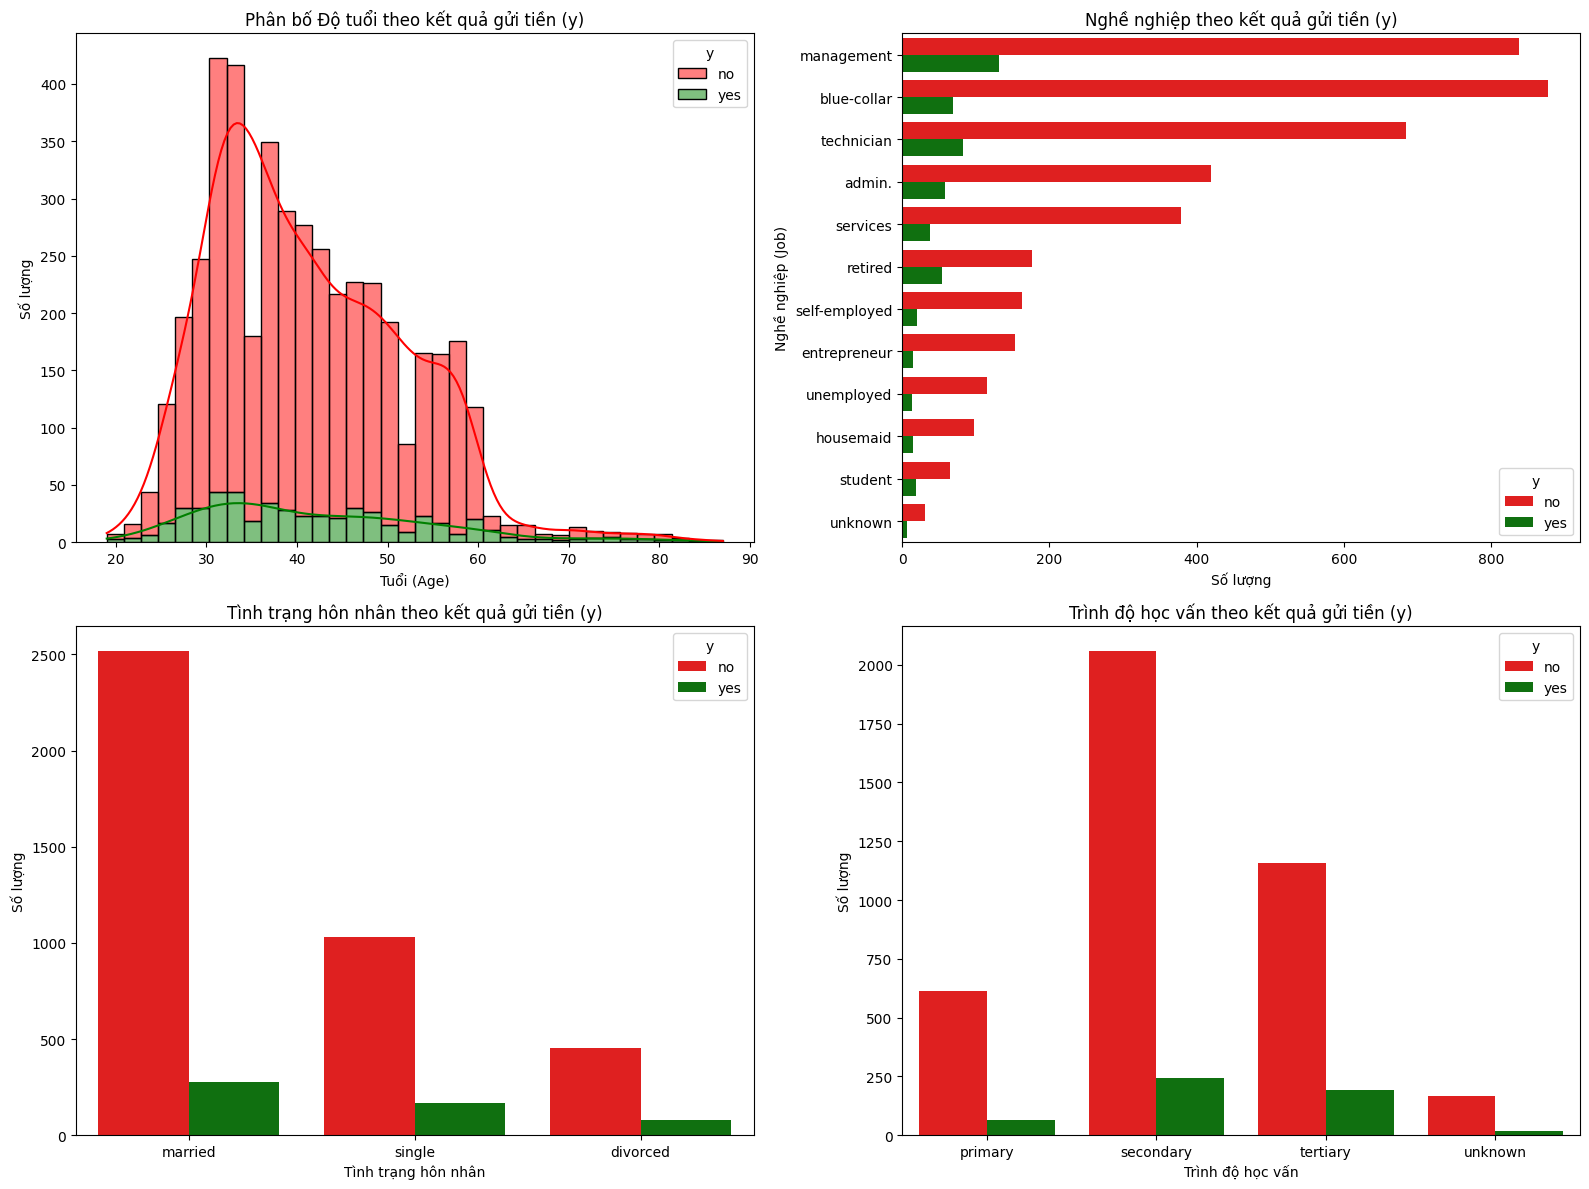

In [4]:
print("Nguyễn Minh Vương - 6451071090")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Phân bố độ tuổi theo nhãn y
sns.histplot(data=df, x='age', hue='y', multiple='stack', ax=axes[0, 0], kde=True, palette={'no': 'red', 'yes': 'green'})
axes[0, 0].set_title('Phân bố Độ tuổi theo kết quả gửi tiền (y)')
axes[0, 0].set_xlabel('Tuổi (Age)')
axes[0, 0].set_ylabel('Số lượng')

# 2. Nghề nghiệp (Job) vs y
job_order = df['job'].value_counts().index
sns.countplot(data=df, y='job', hue='y', order=job_order, ax=axes[0, 1], palette={'no': 'red', 'yes': 'green'})
axes[0, 1].set_title('Nghề nghiệp theo kết quả gửi tiền (y)')
axes[0, 1].set_xlabel('Số lượng')
axes[0, 1].set_ylabel('Nghề nghiệp (Job)')

# 3. Tình trạng hôn nhân (Marital) vs y
sns.countplot(data=df, x='marital', hue='y', ax=axes[1, 0], palette={'no': 'red', 'yes': 'green'})
axes[1, 0].set_title('Tình trạng hôn nhân theo kết quả gửi tiền (y)')
axes[1, 0].set_xlabel('Tình trạng hôn nhân')
axes[1, 0].set_ylabel('Số lượng')

# 4. Trình độ học vấn (Education) vs y
sns.countplot(data=df, x='education', hue='y', ax=axes[1, 1], palette={'no': 'red', 'yes': 'green'})
axes[1, 1].set_title('Trình độ học vấn theo kết quả gửi tiền (y)')
axes[1, 1].set_xlabel('Trình độ học vấn')
axes[1, 1].set_ylabel('Số lượng')

plt.tight_layout()
plt.show()


### Bước 4: Khảo sát mối liên quan giữa các yếu tố tín dụng & tài sản (Default, Housing, Loan) với quyết định gửi tiền (y)

Nguyễn Minh Vương - 6451071090


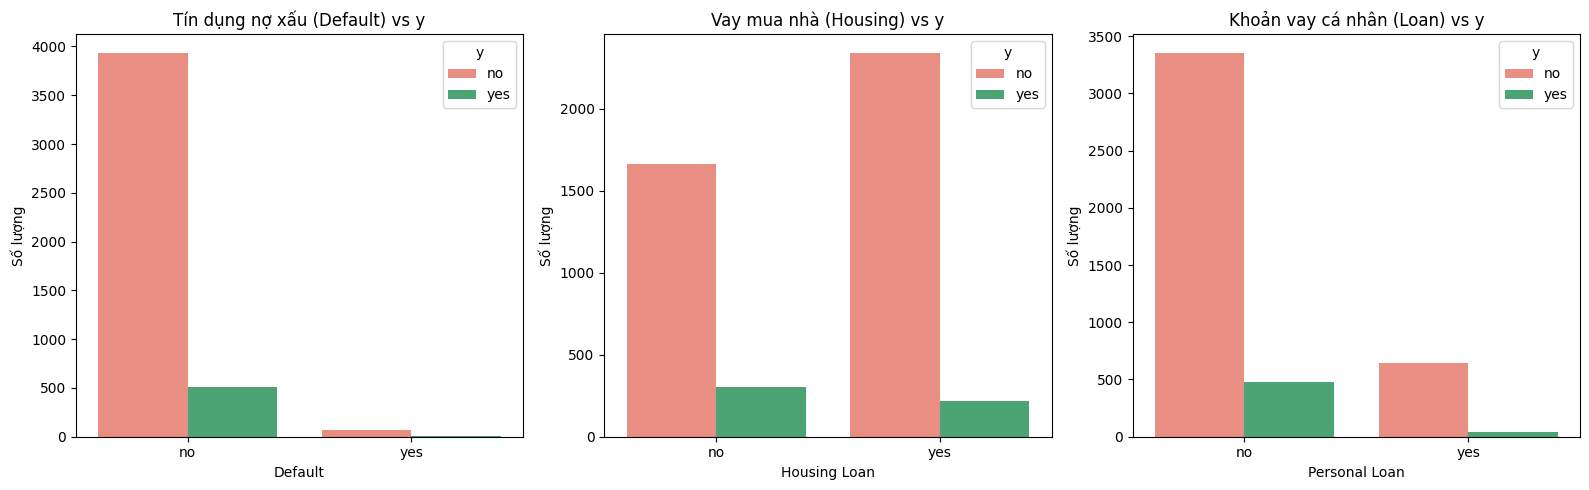

In [5]:
print("Nguyễn Minh Vương - 6451071090")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Tín dụng nợ xấu (Default)
sns.countplot(data=df, x='default', hue='y', ax=axes[0], palette={'no': 'salmon', 'yes': 'mediumseagreen'})
axes[0].set_title('Tín dụng nợ xấu (Default) vs y')
axes[0].set_xlabel('Default')
axes[0].set_ylabel('Số lượng')

# 2. Vay mua nhà (Housing)
sns.countplot(data=df, x='housing', hue='y', ax=axes[1], palette={'no': 'salmon', 'yes': 'mediumseagreen'})
axes[1].set_title('Vay mua nhà (Housing) vs y')
axes[1].set_xlabel('Housing Loan')
axes[1].set_ylabel('Số lượng')

# 3. Vay cá nhân (Loan)
sns.countplot(data=df, x='loan', hue='y', ax=axes[2], palette={'no': 'salmon', 'yes': 'mediumseagreen'})
axes[2].set_title('Khoản vay cá nhân (Loan) vs y')
axes[2].set_xlabel('Personal Loan')
axes[2].set_ylabel('Số lượng')

plt.tight_layout()
plt.show()


### Bước 5: Thống kê và khảo sát thời lượng cuộc gọi (Duration) và số lần liên lạc (Campaign)

Nguyễn Minh Vương - 6451071090


/tmp/ipykernel_19133/2832307784.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y='duration', data=df, palette={'no': 'coral', 'yes': 'lightgreen'})
/tmp/ipykernel_19133/2832307784.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y='campaign', data=df, palette={'no': 'coral', 'yes': 'lightgreen'})


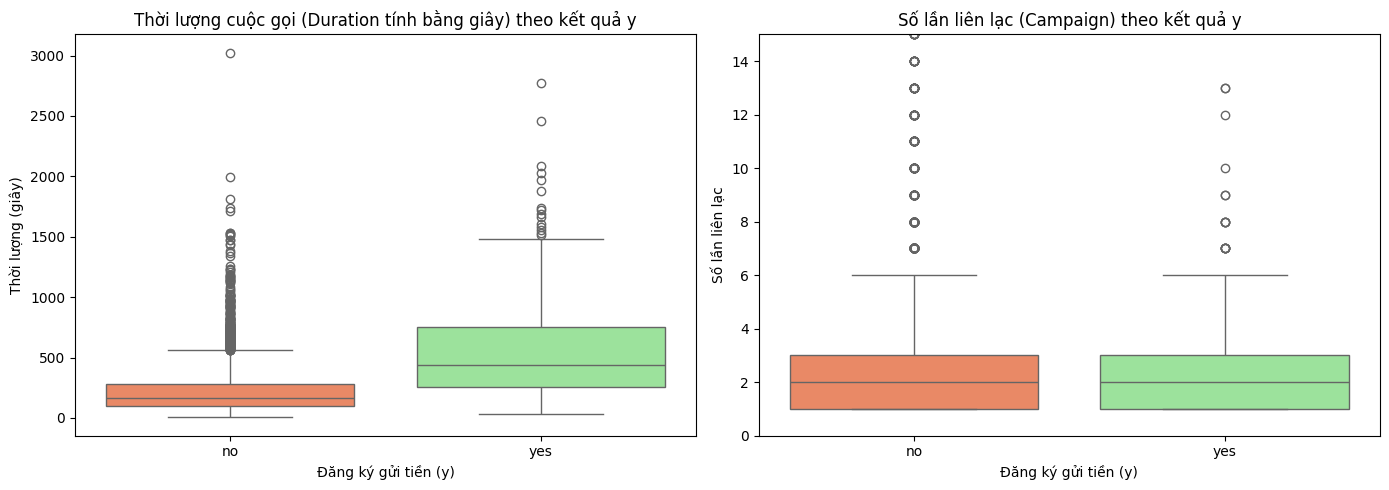

In [6]:
print("Nguyễn Minh Vương - 6451071090")

plt.figure(figsize=(14, 5))

# Biểu đồ thời lượng liên lạc
plt.subplot(1, 2, 1)
sns.boxplot(x='y', y='duration', data=df, palette={'no': 'coral', 'yes': 'lightgreen'})
plt.title('Thời lượng cuộc gọi (Duration tính bằng giây) theo kết quả y')
plt.xlabel('Đăng ký gửi tiền (y)')
plt.ylabel('Thời lượng (giây)')

# Biểu đồ số lần liên lạc trong chiến dịch
plt.subplot(1, 2, 2)
sns.boxplot(x='y', y='campaign', data=df, palette={'no': 'coral', 'yes': 'lightgreen'})
plt.title('Số lần liên lạc (Campaign) theo kết quả y')
plt.xlabel('Đăng ký gửi tiền (y)')
plt.ylabel('Số lần liên lạc')
plt.ylim(0, 15)

plt.tight_layout()
plt.show()


### Bước 6: Tiền xử lý dữ liệu: Xử lý giá trị 'unknown' và xóa thuộc tính không cần thiết

In [7]:
print("Nguyễn Minh Vương - 6451071090")

df_clean = df.copy()

# Điền các giá trị 'unknown' ở các thuộc tính quan trọng bằng giá trị xuất hiện nhiều nhất (mode)
for col in ['job', 'education']:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].replace('unknown', mode_val)

# Xóa bỏ thuộc tính pdays (vì đa số bằng -1 biểu thị chưa từng liên lạc trong quá khứ)
if 'pdays' in df_clean.columns:
    df_clean.drop(columns=['pdays'], inplace=True)

print("Kiểm tra lại số lượng giá trị 'unknown' ở job và education sau khi xử lý:")
print("Job unknown:", (df_clean['job'] == 'unknown').sum())
print("Education unknown:", (df_clean['education'] == 'unknown').sum())
display(df_clean.head())


Nguyễn Minh Vương - 6451071090
Kiểm tra lại số lượng giá trị 'unknown' ở job và education sau khi xử lý:
Job unknown: 0
Education unknown: 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,0,unknown,no


### Bước 7: Biến đổi các thuộc tính (Mã hóa One-Hot Encoding và Rời rạc hóa Độ tuổi)

In [8]:
print("Nguyễn Minh Vương - 6451071090")

# 1. Mã hóa thuộc tính quyết định y thành 0 và 1
df_clean['y'] = df_clean['y'].map({'no': 0, 'yes': 1})

# 2. Rời rạc hóa thuộc tính tuổi (age) thành 5 nhóm
df_clean['age_group'] = pd.cut(df_clean['age'], bins=[0, 30, 40, 50, 60, 100], labels=['<30', '30-40', '40-50', '50-60', '>60'])

# 3. Mã hóa One-hot encoding cho các biến phân loại
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'age_group']
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)

print(f"Kích thước dữ liệu sau One-hot encoding: {df_encoded.shape}")
display(df_encoded.head())


Nguyễn Minh Vương - 6451071090
Kích thước dữ liệu sau One-hot encoding: (4521, 44)


,age,balance,day,duration,campaign,previous,y,job_blue-collar,job_entrepreneur,job_housemaid,...,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,age_group_30-40,age_group_40-50,age_group_50-60,age_group_>60
0,30,1787,19,79,1,0,0,False,False,False,...,False,True,False,False,False,True,False,False,False,False
1,33,4789,11,220,1,4,0,False,False,False,...,False,False,False,False,False,False,True,False,False,False
2,35,1350,16,185,1,1,0,False,False,False,...,False,False,False,False,False,False,True,False,False,False
3,30,1476,3,199,4,0,0,False,False,False,...,False,False,False,False,False,True,False,False,False,False
4,59,0,5,226,1,0,0,True,False,False,...,False,False,False,False,False,True,False,False,True,False


### Bước 8: Tạo thuộc tính mới

In [9]:
print("Nguyễn Minh Vương - 6451071090")

# Tạo thuộc tính tổng số lần tương tác khách hàng
df_encoded['total_contacts'] = df_clean['campaign'] + df_clean['previous']

# Tạo thuộc tính đánh dấu khách hàng đã từng được liên lạc trong chiến dịch trước
df_encoded['was_contacted_before'] = (df_clean['previous'] > 0).astype(int)

print("Các thuộc tính mới vừa tạo:")
display(df_encoded[['total_contacts', 'was_contacted_before', 'y']].head(10))


Nguyễn Minh Vương - 6451071090
Các thuộc tính mới vừa tạo:


,total_contacts,was_contacted_before,y
0,1,0,0
1,5,1,0
2,2,1,0
3,4,0,0
4,1,0,0
5,5,1,0
6,3,1,0
7,2,0,0
8,2,0,0
9,3,1,0
